# Acoustic drone detection — dataset 1

Binary clips from the Kaggle set `amineipad/drone-sound-audio-detection`, stored locally in `dataset/Binary_Drone_Audio`. The folders are the labels: `yes_drone` and `unknown`. Every measurement below is computed from those wav files.

The questions are the ones that change how a detector should be trained: how unbalanced the folders are, whether a "file" is really its own recording, what the negative class actually contains, and whether drone and non-drone differ in level and spectrum or only in the folder name.


## 0. Project setup


In [1]:
%matplotlib inline

import re
import wave
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import textwrap
from IPython.display import Markdown, display

def find_audio_root():
    candidates = [
        Path.cwd() / "dataset" / "Binary_Drone_Audio",
        Path.cwd().parent / "Datasets" / "dataset1-Binary_Drone_Audio",
        Path("/Users/mostafazamaniturk/Documents/USD/AAI-590-capstone/Datasets/dataset1-Binary_Drone_Audio"),
        Path.home() / "Downloads" / "Binary_Drone_Audio",
    ]
    for path in candidates:
        if (path / "yes_drone").is_dir() and (path / "unknown").is_dir():
            return path
    raise FileNotFoundError(
        "Binary_Drone_Audio was not found. Looked in:\n" + "\n".join(str(p) for p in candidates)
    )

AUDIO_ROOT = find_audio_root()

SR_EXPECTED = 16000
N_FFT = 16384  # 1.024 s at 16 kHz, the length of almost every drone clip
LOW_HZ = (0, 300)
MID_HZ = (300, 2000)
HIGH_HZ = (2000, 8000)

LABEL_ORDER = ["yes_drone", "unknown"]
LABEL_NAME = {"yes_drone": "Drone", "unknown": "Unknown"}
LABEL_COLOR = {"yes_drone": "#1f4e79", "unknown": "#e07a2f"}
FAMILY_ORDER = ["B (Bebop)", "Membo", "mixed", "extra", "freesound-style", "silence", "named noise", "other"]
FAMILY_COLOR = {
    "B (Bebop)": "#08306b",
    "Membo": "#4292c6",
    "mixed": "#e6550d",
    "extra": "#7a0177",
    "freesound-style": "#b85c14",
    "silence": "#9e9e9e",
    "named noise": "#2e7d4f",
    "other": "#6b3fa0",
}
NAMED_NOISE = ("doing_the_dishes", "exercise_bike", "running_tap", "pink_noise", "white_noise")
ESC_NAME = re.compile(r"^\d+-\d+-[A-Z]-\d+\.wav$")

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#d5d5d5",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "font.size": 10,
    "axes.titlesize": 12,
    "legend.frameon": False,
})


def show(fig):
    display(fig)
    plt.close(fig)


def family_of(label, name):
    if label == "unknown":
        if name.startswith("silence"):
            return "silence"
        if name.startswith(NAMED_NOISE):
            return "named noise"
        if ESC_NAME.match(name):
            return "freesound-style"
        return "other"
    if name.startswith("mixed"):
        return "mixed"
    if name.startswith("Membo"):
        return "Membo"
    if name.startswith("extra"):
        return "extra"
    if name.startswith("B_"):
        return "B (Bebop)"
    return "other"


def parent_of(name):
    matched = re.match(r"^(.*)_\d+_\.wav$", name)
    if matched:
        return matched.group(1)
    matched = re.match(r"^(extra_membo_D\d+)_\d+\.wav$", name)
    if matched:
        return matched.group(1)
    return Path(name).stem


print(AUDIO_ROOT)


/Users/mostafazamaniturk/Documents/USD/AAI-590-capstone/AAI-590/dataset/Binary_Drone_Audio


## 2.1 Exploratory data analysis

### What is in the folders

A pass over the wav headers only: channel count, sample rate, bit depth, duration, and the filename family. Audio samples are read in the next section.


11,704 files, no unreadable wavs
channels [1]
bytes per sample [2]
sample rate [16000]
any compressed False
on disk 384.0 MB


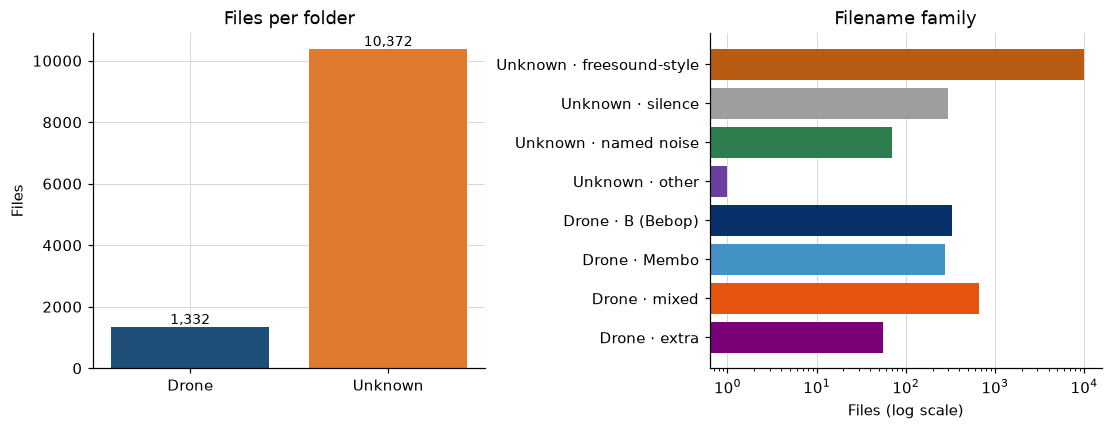

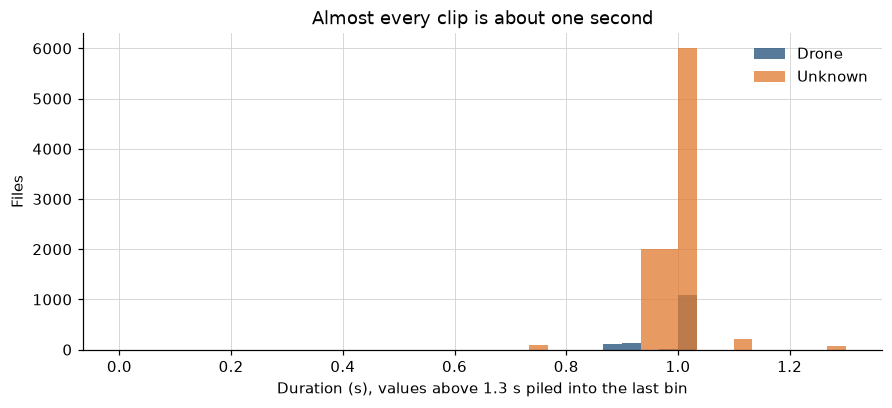

shorter than 0.5 s: 2    longer than 1.3 s: 67
             min  median    max
label                          
unknown    0.002   1.022  5.120
yes_drone  0.650   1.024  1.024
drone parent recordings: 257
slices per parent: min 1 median 5 max 56
parents with more than one slice: 99.6%


In [2]:
rows = []
problems = []
for label in LABEL_ORDER:
    folder = AUDIO_ROOT / label
    if not folder.is_dir():
        problems.append(f"missing folder {folder}")
        continue
    for path in sorted(folder.iterdir()):
        if not path.is_file():
            continue
        try:
            with wave.open(str(path), "rb") as handle:
                channels = handle.getnchannels()
                width = handle.getsampwidth()
                rate = handle.getframerate()
                frames = handle.getnframes()
                comp = handle.getcomptype()
        except wave.Error as exc:
            problems.append(f"{path.name}: {exc}")
            continue
        rows.append({
            "label": label,
            "family": family_of(label, path.name),
            "parent": parent_of(path.name),
            "name": path.name,
            "path": path,
            "channels": channels,
            "width": width,
            "rate": rate,
            "frames": frames,
            "compressed": comp != "NONE",
            "duration_s": frames / rate if rate else np.nan,
            "bytes": path.stat().st_size,
        })

meta = pd.DataFrame(rows)
if problems:
    print("PROBLEMS")
    for item in problems[:20]:
        print(" -", item)
else:
    print(f"{len(meta):,} files, no unreadable wavs")

print("channels", sorted(meta.channels.unique().tolist()))
print("bytes per sample", sorted(meta.width.unique().tolist()))
print("sample rate", sorted(meta.rate.unique().tolist()))
print("any compressed", bool(meta.compressed.any()))
print(f"on disk {meta.bytes.sum() / 1e6:.1f} MB")

counts = meta.groupby("label").size().reindex(LABEL_ORDER)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
axes[0].bar(
    [LABEL_NAME[k] for k in LABEL_ORDER],
    counts.to_numpy(),
    color=[LABEL_COLOR[k] for k in LABEL_ORDER],
)
axes[0].set_ylabel("Files")
axes[0].set_title("Files per folder")
for x, value in enumerate(counts.to_numpy()):
    axes[0].text(x, value, f"{value:,}", ha="center", va="bottom", fontsize=9)

family_counts = meta.groupby(["label", "family"]).size().reset_index(name="n")
family_counts["family"] = pd.Categorical(family_counts["family"], FAMILY_ORDER, ordered=True)
family_counts = family_counts.sort_values(["label", "family"])
y = np.arange(len(family_counts))
axes[1].barh(
    y,
    family_counts["n"],
    color=[FAMILY_COLOR[f] for f in family_counts["family"]],
)
axes[1].set_yticks(y, [f"{LABEL_NAME[r.label]} · {r.family}" for r in family_counts.itertuples()])
axes[1].invert_yaxis()
axes[1].set_xscale("log")
axes[1].set_xlabel("Files (log scale)")
axes[1].set_title("Filename family")
axes[1].grid(axis="y", visible=False)
show(fig)

fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
bins = np.linspace(0, 1.3, 40)
for label in LABEL_ORDER:
    part = meta.loc[meta.label == label, "duration_s"]
    ax.hist(part.clip(upper=1.3), bins=bins, alpha=0.75, label=LABEL_NAME[label], color=LABEL_COLOR[label])
ax.set_xlabel("Duration (s), values above 1.3 s piled into the last bin")
ax.set_ylabel("Files")
ax.set_title("Almost every clip is about one second")
ax.legend()
show(fig)
long = int((meta.duration_s > 1.3).sum())
short = int((meta.duration_s < 0.5).sum())
print(f"shorter than 0.5 s: {short:,}    longer than 1.3 s: {long:,}")
print(meta.groupby("label").duration_s.agg(["min", "median", "max"]).round(3))

drone = meta[meta.label == "yes_drone"]
slices = drone.groupby("parent").size()
print(f"drone parent recordings: {len(slices):,}")
print(f"slices per parent: min {slices.min()} median {slices.median():.0f} max {slices.max()}")
print(f"parents with more than one slice: {(slices > 1).mean():.1%}")


### Level and spectrum

Samples are read as 16-bit mono and scaled to ±1. RMS and peak use the whole file. The spectrum uses the first 1.024 s (16,384 samples), with a Hann window. Clips quieter than −80 dB RMS, or shorter than half a second, are left out of the average spectrum so digital silence does not flatten it. Band shares are fractions of that window's power.


read 0 / 11,704


read 3,000 / 11,704


read 6,000 / 11,704


read 9,000 / 11,704


finished 11,704 files; 10,555 entered the mean spectrum


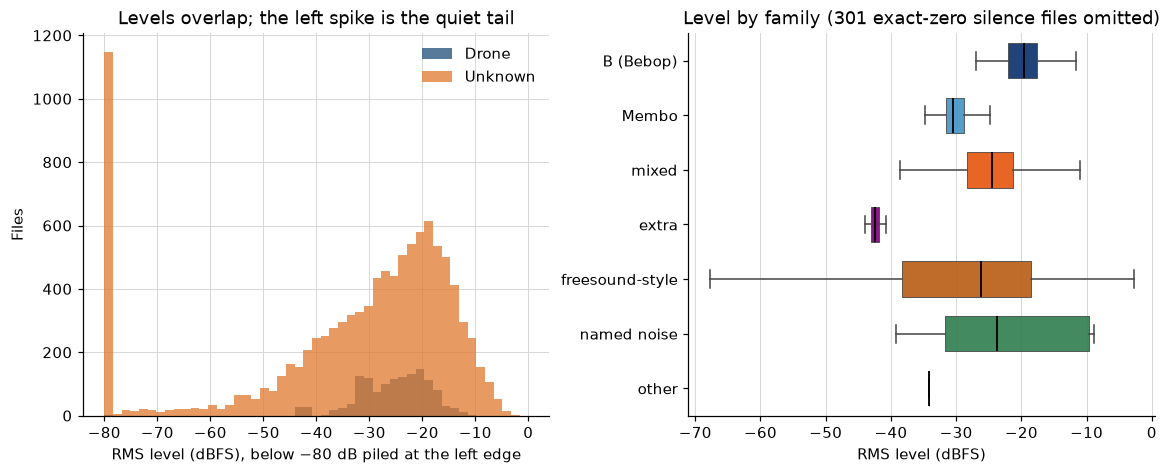

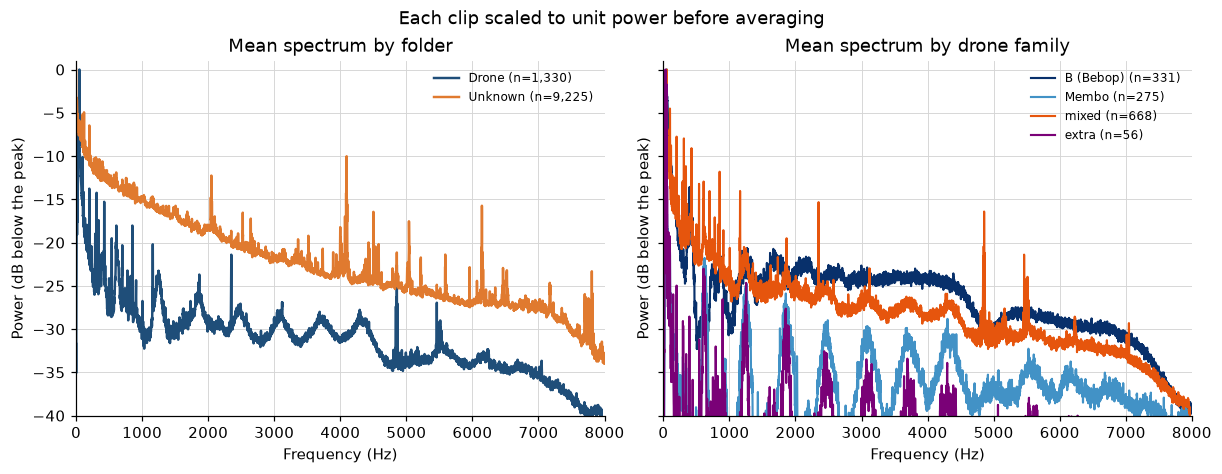

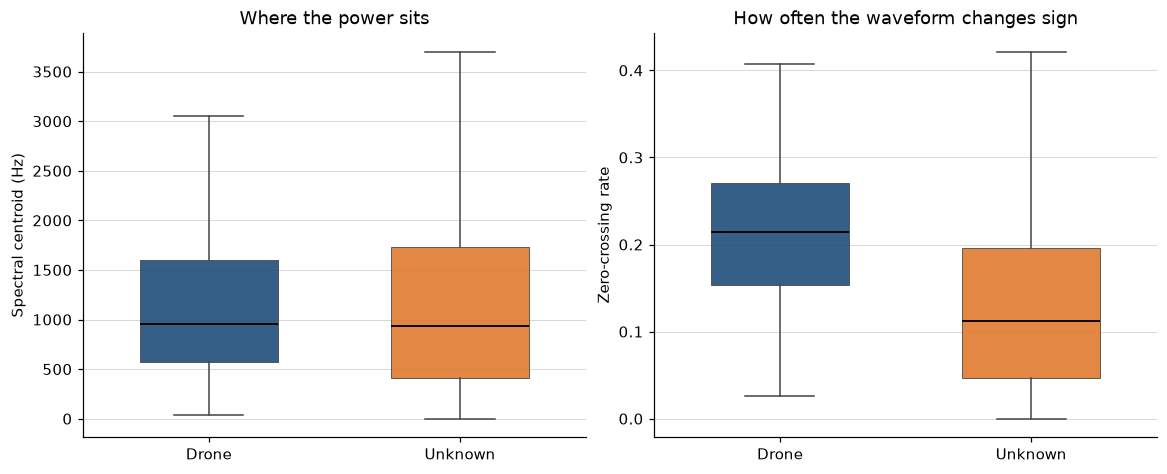

In [3]:
def read_audio(path):
    with wave.open(str(path), "rb") as handle:
        frames = handle.getnframes()
        raw = handle.readframes(frames)
    if frames == 0 or len(raw) < 2:
        return np.zeros(0, dtype=np.float32)
    samples = np.frombuffer(raw, dtype="<i2").astype(np.float32)
    samples *= (1.0 / 32768.0)
    return samples


def window_spectrum(samples):
    clip = samples[:N_FFT]
    if clip.size < N_FFT:
        clip = np.pad(clip, (0, N_FFT - clip.size))
    spectrum = np.fft.rfft(clip * np.hanning(N_FFT))
    return np.abs(spectrum) ** 2


FREQS = np.fft.rfftfreq(N_FFT, d=1 / SR_EXPECTED)
LOW = (FREQS >= LOW_HZ[0]) & (FREQS < LOW_HZ[1])
MID = (FREQS >= MID_HZ[0]) & (FREQS < MID_HZ[1])
HIGH = (FREQS >= HIGH_HZ[0]) & (FREQS < HIGH_HZ[1])

rms_db = np.empty(len(meta), dtype=np.float64)
peak = np.empty(len(meta), dtype=np.float64)
zcr = np.empty(len(meta), dtype=np.float64)
centroid = np.full(len(meta), np.nan)
low_share = np.full(len(meta), np.nan)
mid_share = np.full(len(meta), np.nan)
high_share = np.full(len(meta), np.nan)
used_in_mean = np.zeros(len(meta), dtype=bool)
spec_acc = {label: np.zeros(FREQS.size, dtype=np.float64) for label in LABEL_ORDER}
spec_n = {label: 0 for label in LABEL_ORDER}
family_acc = {name: np.zeros(FREQS.size, dtype=np.float64) for name in FAMILY_ORDER}
family_n = {name: 0 for name in FAMILY_ORDER}

for i, row in enumerate(meta.itertuples(index=False)):
    samples = read_audio(row.path)
    if samples.size == 0:
        rms_db[i] = -120
        peak[i] = 0
        zcr[i] = 0
        continue
    rms = float(np.sqrt(np.mean(samples ** 2)))
    rms_db[i] = 20 * np.log10(max(rms, 1e-12))
    peak[i] = float(np.max(np.abs(samples)))
    zcr[i] = float(np.mean(samples[1:] * samples[:-1] < 0)) if samples.size > 1 else 0.0
    power = window_spectrum(samples)
    total = float(power.sum())
    if total > 0:
        centroid[i] = float(np.sum(FREQS * power) / total)
        low_share[i] = float(power[LOW].sum() / total)
        mid_share[i] = float(power[MID].sum() / total)
        high_share[i] = float(power[HIGH].sum() / total)
    if rms >= 1e-4 and samples.size >= 8000 and total > 0:
        norm = power / total
        spec_acc[row.label] += norm
        spec_n[row.label] += 1
        family_acc[row.family] += norm
        family_n[row.family] += 1
        used_in_mean[i] = True
    if i % 3000 == 0:
        print(f"read {i:,} / {len(meta):,}")

meta = meta.copy()
meta["rms_db"] = rms_db
meta["peak"] = peak
meta["zcr"] = zcr
meta["centroid_hz"] = centroid
meta["low_share"] = low_share
meta["mid_share"] = mid_share
meta["high_share"] = high_share
meta["in_mean_spectrum"] = used_in_mean
print(f"finished {len(meta):,} files; {int(used_in_mean.sum()):,} entered the mean spectrum")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), layout="constrained")
bins = np.linspace(-80, 0, 50)
for label in LABEL_ORDER:
    axes[0].hist(
        meta.loc[meta.label == label, "rms_db"].clip(-80, 0),
        bins=bins, alpha=0.75, label=LABEL_NAME[label], color=LABEL_COLOR[label],
    )
axes[0].set_xlabel("RMS level (dBFS), below −80 dB piled at the left edge")
axes[0].set_ylabel("Files")
axes[0].set_title("Levels overlap; the left spike is the quiet tail")
axes[0].legend()

order = [f for f in FAMILY_ORDER if f != "silence" and (meta.family == f).any()]
arrays = [meta.loc[meta.family == name, "rms_db"].to_numpy() for name in reversed(order)]
bp = axes[1].boxplot(
    arrays,
    orientation="horizontal",
    tick_labels=list(reversed(order)),
    showfliers=False,
    patch_artist=True,
    widths=0.65,
    medianprops={"color": "black", "linewidth": 1.2},
    whiskerprops={"color": "#444444"},
    capprops={"color": "#444444"},
    boxprops={"linewidth": 0.6, "color": "#444444"},
)
for patch, name in zip(bp["boxes"], reversed(order)):
    patch.set_facecolor(FAMILY_COLOR[name])
    patch.set_alpha(0.9)
axes[1].set_xlabel("RMS level (dBFS)")
axes[1].set_title("Level by family (301 exact-zero silence files omitted)")
axes[1].grid(axis="y", visible=False)
show(fig)

def db_from_acc(acc, n):
    if n == 0:
        return None
    mean = acc / n
    mean = mean / mean.max()
    return 10 * np.log10(np.maximum(mean, 1e-12))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained", sharey=True)
for label in LABEL_ORDER:
    curve = db_from_acc(spec_acc[label], spec_n[label])
    axes[0].plot(FREQS, curve, color=LABEL_COLOR[label], label=f"{LABEL_NAME[label]} (n={spec_n[label]:,})", lw=1.6)
axes[0].set_title("Mean spectrum by folder")
for name in ["B (Bebop)", "Membo", "mixed", "extra"]:
    curve = db_from_acc(family_acc[name], family_n[name])
    if curve is None:
        continue
    axes[1].plot(FREQS, curve, color=FAMILY_COLOR[name], label=f"{name} (n={family_n[name]:,})", lw=1.4)
axes[1].set_title("Mean spectrum by drone family")
for ax in axes:
    ax.set_xlim(0, 8000)
    ax.set_ylim(-40, 1)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Power (dB below the peak)")
    ax.legend(fontsize=8)
fig.suptitle("Each clip scaled to unit power before averaging", fontsize=12)
show(fig)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), layout="constrained")
for ax, column, xlabel, title in (
    (axes[0], "centroid_hz", "Spectral centroid (Hz)", "Where the power sits"),
    (axes[1], "zcr", "Zero-crossing rate", "How often the waveform changes sign"),
):
    arrays = [meta.loc[meta.label == label, column].dropna().to_numpy() for label in LABEL_ORDER]
    bp = ax.boxplot(
        arrays,
        tick_labels=[LABEL_NAME[label] for label in LABEL_ORDER],
        showfliers=False,
        patch_artist=True,
        widths=0.55,
        medianprops={"color": "black", "linewidth": 1.2},
        whiskerprops={"color": "#444444"},
        capprops={"color": "#444444"},
        boxprops={"linewidth": 0.6, "color": "#444444"},
    )
    for patch, label in zip(bp["boxes"], LABEL_ORDER):
        patch.set_facecolor(LABEL_COLOR[label])
        patch.set_alpha(0.9)
    ax.set_ylabel(xlabel)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
show(fig)


### A few clips, heard as pictures

Each panel is one file whose RMS is closest to the median of its family, among clips that entered the mean spectrum. The spectrogram is a 512-point Hann STFT (32 ms window, 8 ms hop), drawn in dB relative to that clip's own peak.


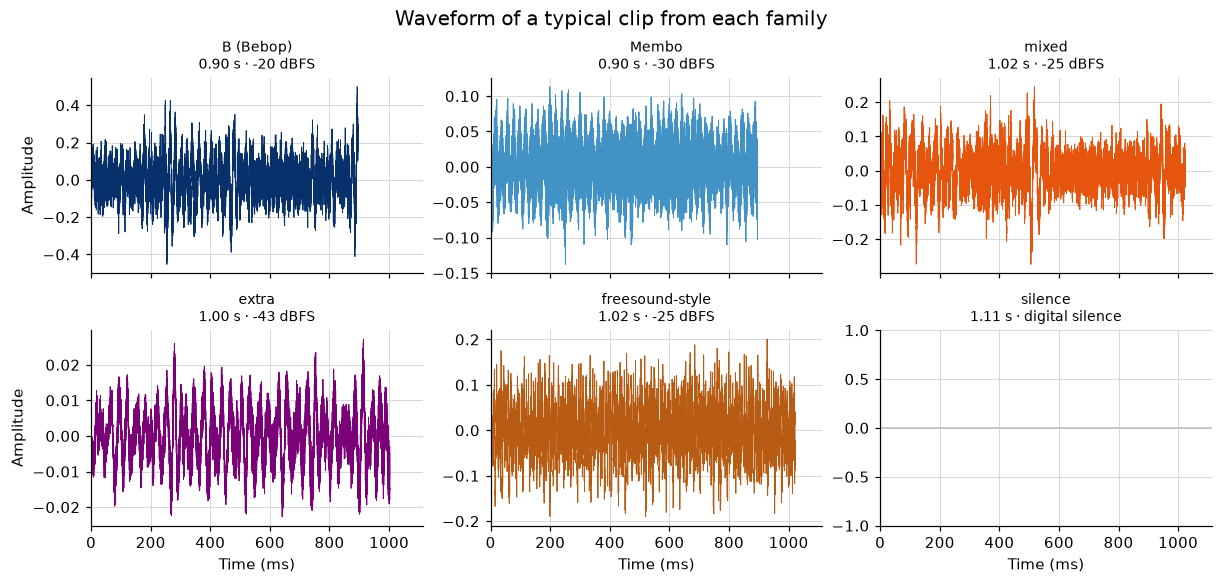

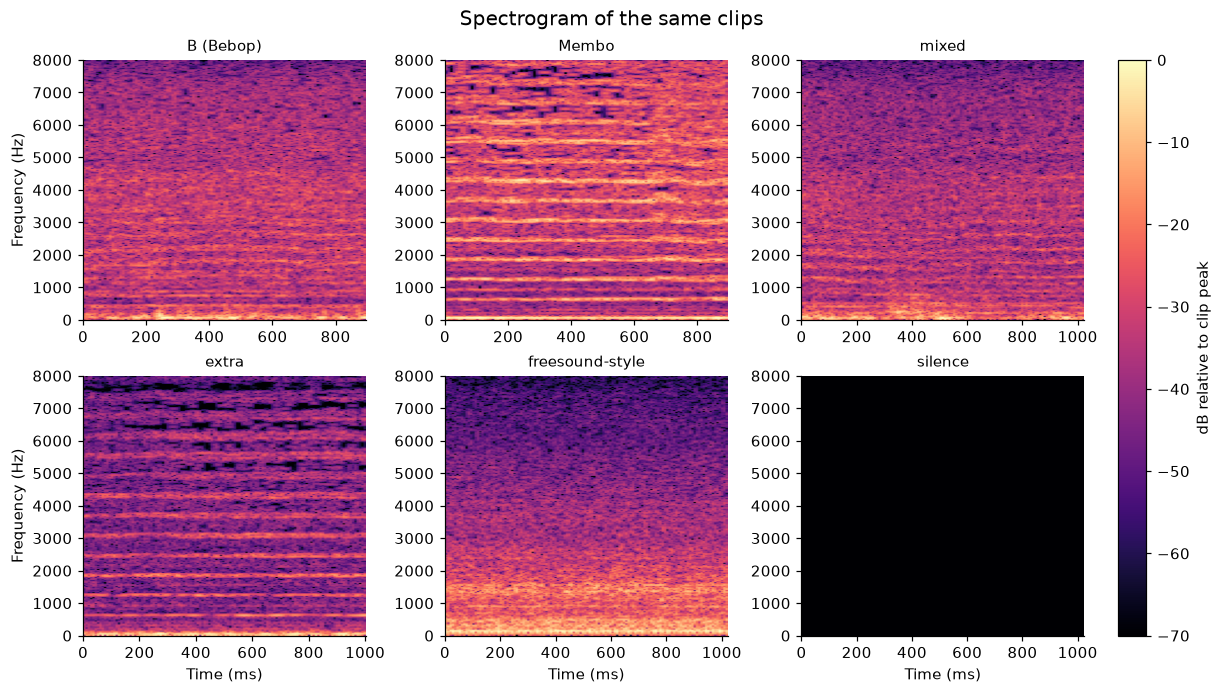

In [4]:
def pick(family):
    pool = meta[(meta.family == family) & meta.in_mean_spectrum]
    if pool.empty:
        pool = meta[meta.family == family]
    median = pool.rms_db.median()
    return pool.iloc[(pool.rms_db - median).abs().argmin()]


show_families = ["B (Bebop)", "Membo", "mixed", "extra", "freesound-style", "silence"]
chosen = [pick(name) for name in show_families]


def spectrogram_db(samples, n_fft=512, hop=128):
    if samples.size < n_fft:
        samples = np.pad(samples, (0, n_fft - samples.size))
    window = np.hanning(n_fft)
    frames = 1 + (samples.size - n_fft) // hop
    grid = np.empty((n_fft // 2 + 1, frames), dtype=np.float64)
    for i in range(frames):
        start = i * hop
        grid[:, i] = np.abs(np.fft.rfft(samples[start:start + n_fft] * window))
    peak = float(grid.max())
    if peak <= 0:
        return np.full_like(grid, -70.0)
    return 20 * np.log10(grid / peak + 1e-12)


fig, axes = plt.subplots(2, 3, figsize=(11, 5.2), layout="constrained", sharex=True)
for ax, row in zip(axes.ravel(), chosen):
    samples = read_audio(row.path)
    t_ms = np.arange(samples.size) / SR_EXPECTED * 1e3
    ax.plot(t_ms, samples, color=FAMILY_COLOR[row.family], lw=0.6)
    level = "digital silence" if row.rms_db < -120 else f"{row.rms_db:.0f} dBFS"
    ax.set_title(f"{row.family}\n{row.duration_s:.2f} s · {level}", fontsize=9)
    ax.set_xlim(0, max(t_ms[-1] if t_ms.size else 0, 1))
    if row.rms_db < -120:
        ax.set_ylim(-1, 1)
for ax in axes[-1]:
    ax.set_xlabel("Time (ms)")
for ax in axes[:, 0]:
    ax.set_ylabel("Amplitude")
fig.suptitle("Waveform of a typical clip from each family", fontsize=13)
show(fig)

fig, axes = plt.subplots(2, 3, figsize=(11, 6.2), layout="constrained")
image = None
for ax, row in zip(axes.ravel(), chosen):
    samples = read_audio(row.path)
    shown = samples[:N_FFT]
    db = spectrogram_db(shown)
    duration_ms = shown.size / SR_EXPECTED * 1e3
    image = ax.imshow(
        db, origin="lower", aspect="auto",
        extent=(0, duration_ms, 0, SR_EXPECTED / 2),
        vmin=-70, vmax=0, cmap="magma",
    )
    ax.set_ylim(0, 8000)
    ax.set_title(row.family, fontsize=10)
    ax.grid(False)
for ax in axes[-1]:
    ax.set_xlabel("Time (ms)")
for ax in axes[:, 0]:
    ax.set_ylabel("Frequency (Hz)")
fig.colorbar(image, ax=axes.ravel().tolist(), fraction=0.03, pad=0.02, label="dB relative to clip peak")
fig.suptitle("Spectrogram of the same clips", fontsize=13)
show(fig)


### Summary


In [5]:
def median(frame, column):
    return float(frame[column].median())


drone = meta[meta.label == "yes_drone"]
unknown = meta[meta.label == "unknown"]
silence = meta[meta.family == "silence"]
audible_unknown = unknown[unknown.family != "silence"]
slices = drone.groupby("parent").size()
long_unknown = int((unknown.duration_s > 1.3).sum())
short_unknown = int((unknown.duration_s < 0.5).sum())
n_digital_silence = int((silence.rms_db < -120).sum())
quiet_unknown = int((unknown.rms_db < -60).sum())

rows = []
for label in LABEL_ORDER:
    part = meta[meta.label == label]
    rows.append({
        "Folder": LABEL_NAME[label],
        "Files": int(len(part)),
        "Hours": part.duration_s.sum() / 3600,
        "Median duration (s)": part.duration_s.median(),
        "Median RMS (dBFS)": part.rms_db.median(),
        "Median centroid (Hz)": part.centroid_hz.median(),
        "Median power below 300 Hz": part.low_share.median(),
        "Median power 0.3–2 kHz": part.mid_share.median(),
        "Median power 2–8 kHz": part.high_share.median(),
    })
summary = pd.DataFrame(rows)
display(summary.style.format({
    "Files": "{:,}",
    "Hours": "{:.2f}",
    "Median duration (s)": "{:.3f}",
    "Median RMS (dBFS)": "{:.1f}",
    "Median centroid (Hz)": "{:.0f}",
    "Median power below 300 Hz": "{:.2f}",
    "Median power 0.3–2 kHz": "{:.2f}",
    "Median power 2–8 kHz": "{:.2f}",
}).hide(axis="index"))

n_trailing_codes = unknown.loc[unknown.family == "freesound-style", "name"].str.extract(r"-(\d+)\.wav$")[0].nunique()
text = f'''
The folder holds **{len(meta):,}** mono 16-bit wavs at **{int(meta.rate.mode().iloc[0]):,} Hz**, **{meta.bytes.sum() / 1e6:.0f} MB** on disk. **{len(drone):,}** are drone and **{len(unknown):,}** are unknown, so unknown is **{len(unknown) / len(drone):.1f}×** larger. A model that always says "unknown" is already right about **{len(unknown) / len(meta):.0%}** of files.

**The drone files are slices, not independent flights.** {len(slices):,} parent names cover the {len(drone):,} drone files. The median parent has **{slices.median():.0f}** slices and {int((slices > 1).sum())} of {len(slices)} parents have more than one. A random split of files puts neighboring seconds of the same recording on both sides of the split.

**Unknown is not one kind of sound.** {int((unknown.family == "freesound-style").sum()):,} files use Freesound-style names (`fold-id-take-code.wav`) spread across {n_trailing_codes} trailing codes. Another **{len(silence):,}** files are named `silence`, and **{int((unknown.family == "named noise").sum()):,}** are named noise (dishes, exercise bike, tap, pink noise, white noise). All **{n_digital_silence}** silence files are digital zeros. The other unknown files have median RMS **{median(audible_unknown, "rms_db"):.0f} dBFS**, next to the drone median of **{median(drone, "rms_db"):.0f} dBFS**. {short_unknown:,} unknown files are shorter than 0.5 s and {long_unknown:,} are longer than 1.3 s; drone duration stays between {drone.duration_s.min():.2f} s and {drone.duration_s.max():.2f} s.

**Median loudness barely separates the folders.** Median RMS is {median(drone, "rms_db"):.1f} dBFS for drone and {median(unknown, "rms_db"):.1f} dBFS for unknown, and the histograms overlap. Unknown also has a quiet tail: {quiet_unknown:,} unknown files are below −60 dBFS, including the digital silence. **Spectrum shape is the clearer difference.** Median share of power below 300 Hz is {median(drone, "low_share"):.2f} for drone and {median(unknown, "low_share"):.2f} for unknown. The drone mean spectrum is a low hum plus harmonics; the unknown mean spectrum is smoother. Bebop and mixed stay broad, while Membo and extra are more tonal. Median centroids are close ({median(drone, "centroid_hz"):.0f} Hz versus {median(unknown, "centroid_hz"):.0f} Hz), so that one number hides the harmonic structure. A loudness threshold will not separate these folders.
'''
display(Markdown(textwrap.dedent(text).strip()))


Folder,Files,Hours,Median duration (s),Median RMS (dBFS),Median centroid (Hz),Median power below 300 Hz,Median power 0.3–2 kHz,Median power 2–8 kHz
Drone,"1,332",0.37,1.024,-24.6,958,0.60,0.16,0.17
Unknown,"10,372",2.96,1.022,-26.8,938,0.22,0.41,0.08


The folder holds **11,704** mono 16-bit wavs at **16,000 Hz**, **384 MB** on disk. **1,332** are drone and **10,372** are unknown, so unknown is **7.8×** larger. A model that always says "unknown" is already right about **89%** of files.

**The drone files are slices, not independent flights.** 257 parent names cover the 1,332 drone files. The median parent has **5** slices and 256 of 257 parents have more than one. A random split of files puts neighboring seconds of the same recording on both sides of the split.

**Unknown is not one kind of sound.** 10,000 files use Freesound-style names (`fold-id-take-code.wav`) spread across 250 trailing codes. Another **301** files are named `silence`, and **70** are named noise (dishes, exercise bike, tap, pink noise, white noise). All **301** silence files are digital zeros. The other unknown files have median RMS **-26 dBFS**, next to the drone median of **-25 dBFS**. 2 unknown files are shorter than 0.5 s and 67 are longer than 1.3 s; drone duration stays between 0.65 s and 1.02 s.

**Median loudness barely separates the folders.** Median RMS is -24.6 dBFS for drone and -26.8 dBFS for unknown, and the histograms overlap. Unknown also has a quiet tail: 1,349 unknown files are below −60 dBFS, including the digital silence. **Spectrum shape is the clearer difference.** Median share of power below 300 Hz is 0.60 for drone and 0.22 for unknown. The drone mean spectrum is a low hum plus harmonics; the unknown mean spectrum is smoother. Bebop and mixed stay broad, while Membo and extra are more tonal. Median centroids are close (958 Hz versus 938 Hz), so that one number hides the harmonic structure. A loudness threshold will not separate these folders.

## 2.2 Data pre-processing

Fix the length of every clip and assign the split. The spectrogram is built in the next section.

A file is not an independent example. Drone names such as `B_S2_D1_067-bebop_000_.wav` are one-second slices of a longer take, and the unknown Freesound-style names repeat the same recording id across several slices and takes. A split that shuffles files puts those slices on both sides of the split. That is leakage, and this split does not do it.

Rules enforced below:

- Every file is assigned to its source recording.
- Files with the same non-silent audio are merged into that recording.
- An all-zero slice is dropped, and it is not an identity. Many unknown recordings end on the same silent slice; treating that slice as a shared recording would chain unrelated sources into one group.
- The whole recording goes to train, validation, or test. It is never divided.
- Windows are cut only after that assignment, and they inherit the recording's split.
- This section saves the window list. It does not compute a spectrogram.


In [6]:
import hashlib
import numpy as np
import pandas as pd

SPLIT_SEED = 42
SPLIT_RATIOS = (0.70, 0.15, 0.15)
TARGET_SAMPLES = 16_000  # 1.0 s at 16 kHz
MIN_SAMPLES = 8_000      # shorter clips are dropped rather than mostly padded
LABEL_ID = {"unknown": 0, "yes_drone": 1}

PROCESSED_DIR = AUDIO_ROOT.parent / "dataset1-processed"


def recording_id(label, name):
    """Identity of the source recording. Slices of one take share this id."""
    matched = re.match(r"^(.*)_\d+_\.wav$", name)
    if matched and label == "yes_drone":
        return "drone:" + matched.group(1)
    matched = re.match(r"^(extra_membo_D\d+)_\d+\.wav$", name)
    if matched:
        return "drone:" + matched.group(1)
    matched = re.match(r"^\d+-(\d+)-[A-Z]-\d+_?\.wav$", name)
    if matched:
        # Same Freesound id can appear as several takes (A, B, C) and several slices.
        return "fs:" + matched.group(1)
    matched = re.match(
        r"^(doing_the_dishes|exercise_bike|running_tap|pink_noise|white_noise)\d+\.wav$",
        name,
    )
    if matched:
        return "noise:" + matched.group(1)
    if name.startswith("silence"):
        return "silence"
    return "file:" + name


def file_md5(path):
    digest = hashlib.md5()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


class UnionFind:
    def __init__(self, items):
        self.parent = {item: item for item in items}

    def find(self, item):
        root = item
        while self.parent[root] != root:
            root = self.parent[root]
        while self.parent[item] != root:
            self.parent[item], item = root, self.parent[item]
        return root

    def union(self, left, right):
        left, right = self.find(left), self.find(right)
        if left != right:
            self.parent[right] = left


files = []
for label in ("yes_drone", "unknown"):
    folder = AUDIO_ROOT / label
    for path in sorted(folder.glob("*.wav")):
        with wave.open(str(path), "rb") as handle:
            frames = handle.getnframes()
            rate = handle.getframerate()
            width = handle.getsampwidth()
            raw = handle.readframes(frames)
        silent = True
        if raw and width == 2:
            pcm = np.frombuffer(raw, dtype="<i2")
            silent = pcm.size == 0 or int(np.max(np.abs(pcm))) == 0
        files.append({
            "path": path,
            "filename": path.name,
            "label": label,
            "label_id": LABEL_ID[label],
            "recording_id": recording_id(label, path.name),
            "n_samples": frames,
            "duration_s": frames / rate,
            "md5": file_md5(path),
            "silent": silent,
        })

files = pd.DataFrame(files)
recordings = sorted(files.recording_id.unique())
groups = UnionFind(recordings)
hash_owner = {}
cross_label = []
merged_hashes = 0
for row in files.itertuples(index=False):
    # Exact zeros share a hash across unrelated recordings (a trailing silent slice).
    # That hash is not a recording identity. The slice is dropped later.
    if row.silent:
        continue
    previous = hash_owner.get(row.md5)
    if previous is None:
        hash_owner[row.md5] = row.recording_id
        continue
    if previous == row.recording_id:
        continue
    previous_label = files.loc[files.recording_id == previous, "label"].iloc[0]
    if previous_label != row.label:
        cross_label.append((row.filename, previous, row.recording_id))
        continue
    groups.union(previous, row.recording_id)
    merged_hashes += 1

if cross_label:
    raise RuntimeError(
        "Identical audio is labeled both drone and unknown, so a safe split cannot be built: "
        + ", ".join(name for name, _, _ in cross_label[:8])
    )

files["group_id"] = files.recording_id.map(groups.find)
label_per_group = files.groupby("group_id").label.nunique()
if (label_per_group > 1).any():
    raise RuntimeError("A recording group contains both labels.")

group_table = (
    files.groupby("group_id")
    .agg(label=("label", "first"), n_files=("filename", "size"))
    .reset_index()
)

rng = np.random.default_rng(SPLIT_SEED)
assignment = {}
for label, part in group_table.groupby("label"):
    order = part.group_id.to_numpy().copy()
    rng.shuffle(order)
    n = len(order)
    n_train = int(round(n * SPLIT_RATIOS[0]))
    n_val = int(round(n * SPLIT_RATIOS[1]))
    if n >= 3:
        n_train = min(max(n_train, 1), n - 2)
        n_val = min(max(n_val, 1), n - n_train - 1)
    else:
        raise RuntimeError(f"Label {label} has only {n} recordings; it cannot fill three splits.")
    for group_id in order[:n_train]:
        assignment[group_id] = "train"
    for group_id in order[n_train:n_train + n_val]:
        assignment[group_id] = "val"
    for group_id in order[n_train + n_val:]:
        assignment[group_id] = "test"

files["split"] = files.group_id.map(assignment)
if files.split.isna().any():
    raise RuntimeError("Some files were not assigned a split.")

# Leakage gates. Any failure stops the cell before the window list is written.
split_count = files.groupby("group_id").split.nunique()
if (split_count > 1).any():
    raise RuntimeError("A recording was assigned to more than one split.")
for left, right in (("train", "val"), ("train", "test"), ("val", "test")):
    shared = set(files.loc[files.split == left, "group_id"]) & set(files.loc[files.split == right, "group_id"])
    if shared:
        raise RuntimeError(f"{left} and {right} share {len(shared)} recordings.")
audible = files.loc[~files.silent]
hash_splits = audible.groupby("md5").split.nunique()
if len(hash_splits) and (hash_splits > 1).any():
    raise RuntimeError("Identical non-silent audio appears in more than one split.")

def window_specs(n_samples):
    """Non-overlapping 1.0 s windows. A short remainder is not its own clip."""
    if n_samples < MIN_SAMPLES:
        return []
    if n_samples < TARGET_SAMPLES:
        return [(0, int(n_samples), True)]
    return [
        (start, TARGET_SAMPLES, False)
        for start in range(0, n_samples - TARGET_SAMPLES + 1, TARGET_SAMPLES)
    ]


window_rows = []
n_silence = int(files.silent.sum())
n_short = 0
n_padded = 0
for row in files.itertuples(index=False):
    if row.silent:
        continue
    pieces = window_specs(int(row.n_samples))
    if not pieces:
        n_short += 1
        continue
    for index, (start, n_samples, padded) in enumerate(pieces):
        if padded:
            n_padded += 1
        window_rows.append({
            "split": row.split,
            "label": row.label,
            "label_id": row.label_id,
            "group_id": row.group_id,
            "filename": row.filename,
            "window_index": index,
            "start_sample": start,
            "n_samples": n_samples,
            "padded": padded,
        })

windows = pd.DataFrame(window_rows)
windows["row"] = windows.groupby("split").cumcount()
if windows.groupby("group_id").split.nunique().max() != 1:
    raise RuntimeError("The window list places one recording in two splits.")
if windows.groupby("filename").split.nunique().max() != 1:
    raise RuntimeError("The window list places one file in two splits.")

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FEATURES_DIR = Path.cwd() / "features"
for folder in (PROCESSED_DIR, FEATURES_DIR):
    for split_name in ("train", "val", "test"):
        for kind in ("logmel", "label"):
            stale = folder / f"{split_name}_{kind}.npy"
            if stale.exists():
                stale.unlink()
    for name in ("train_logmel_mean.npy", "train_logmel_std.npy"):
        stale = folder / name
        if stale.exists():
            stale.unlink()

windows.to_csv(PROCESSED_DIR / "windows.csv", index=False)
files.drop(columns=["path"]).to_csv(PROCESSED_DIR / "files.csv", index=False)

summary = (
    windows.groupby(["split", "label"])
    .agg(windows=("filename", "size"), recordings=("group_id", "nunique"), files=("filename", "nunique"))
    .reindex(pd.MultiIndex.from_product(
        [("train", "val", "test"), ("yes_drone", "unknown")],
        names=["split", "label"],
    ))
    .fillna(0)
    .astype(int)
    .reset_index()
)
display(summary)

print(f"Source audio: {AUDIO_ROOT}")
print(f"Window list: {PROCESSED_DIR / 'windows.csv'}")
print(f"Recordings: {files.group_id.nunique():,} from {files.recording_id.nunique():,} filename groups")
print(f"Identical files merged across filename groups: {merged_hashes:,}")
print(f"Digital silence excluded: {n_silence:,}    clips shorter than 0.5 s excluded: {n_short:,}")
print(f"Windows zero-padded because the clip was under 1.0 s: {n_padded:,}")
print("Label: unknown = 0, drone = 1")
held = {name: set(files.loc[files.split == name, "group_id"]) for name in ("train", "val", "test")}
overlap = len(held["train"] & held["val"]) + len(held["train"] & held["test"]) + len(held["val"] & held["test"])
print(f"Recording overlap between train, validation, and test: {overlap}")
print("Spectrograms are computed in the next section, from this window list.")


,split,label,windows,recordings,files
0,train,yes_drone,896,180,896
1,train,unknown,6745,1071,6538
2,val,yes_drone,246,39,246
3,val,unknown,1375,230,1375
4,test,yes_drone,190,38,190
5,test,unknown,1369,229,1369


Source audio: /Users/mostafazamaniturk/Documents/USD/AAI-590-capstone/AAI-590/dataset/Binary_Drone_Audio
Window list: /Users/mostafazamaniturk/Documents/USD/AAI-590-capstone/AAI-590/dataset/dataset1-processed/windows.csv
Recordings: 1,788 from 1,788 filename groups
Identical files merged across filename groups: 0
Digital silence excluded: 1,089    clips shorter than 0.5 s excluded: 1
Windows zero-padded because the clip was under 1.0 s: 3,765
Label: unknown = 0, drone = 1
Recording overlap between train, validation, and test: 0
Spectrograms are computed in the next section, from this window list.


## 3. Feature extraction

Each 1.0 s window from the split above becomes one log-mel spectrogram. That spectrogram is the transformer input.

The mel filterbank is fixed: 128 bins, a 25 ms window, a 10 ms hop, from 20 Hz to 8 kHz. Nothing in the filterbank is estimated from these clips. After the spectrograms are built, each mel bin is scaled by the mean and standard deviation of the **training** windows. Validation and test use that same scale. They do not contribute to it.

The spectrograms, labels, and the training scale are written to `features/`.


,split,windows,mel bins,frames
0,train,7641,128,98
1,val,1621,128,98
2,test,1559,128,98


Saved log-mel tensors: /Users/mostafazamaniturk/Documents/USD/AAI-590-capstone/AAI-590/features
Feature: log-mel, 128 bins, 25 ms window, 10 ms hop, log(power + 1e-6)
Scale: per-bin mean and standard deviation of the training windows only
Validation and test were scaled with that training scale and did not contribute to it.
Label: unknown = 0, drone = 1


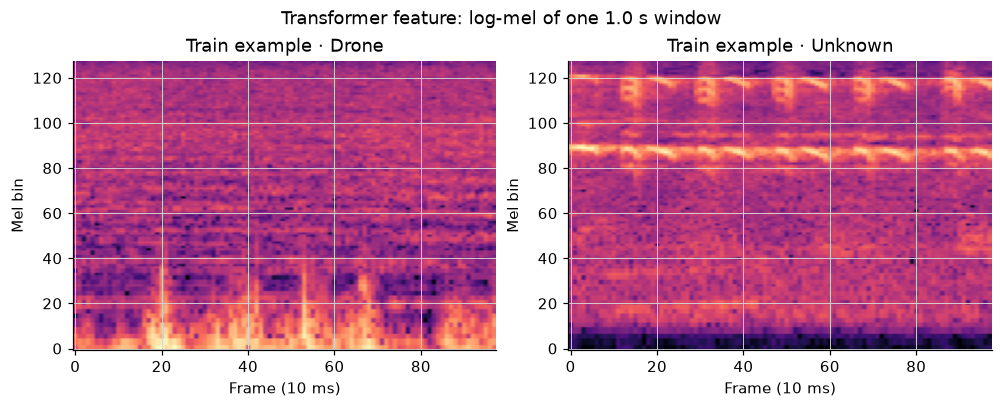

In [7]:
N_MELS = 128
N_FFT_MEL = 400  # 25 ms at 16 kHz
HOP_MEL = 160    # 10 ms
FMIN = 20.0
FMAX = 8_000.0
FEATURES_DIR = Path.cwd() / "features"
FEATURES_DIR.mkdir(parents=True, exist_ok=True)


def read_pcm(path):
    with wave.open(str(path), "rb") as handle:
        if handle.getnchannels() != 1 or handle.getsampwidth() != 2:
            raise ValueError(f"{path.name} is not mono 16-bit PCM")
        rate = handle.getframerate()
        raw = handle.readframes(handle.getnframes())
    if rate != SR_EXPECTED:
        raise ValueError(f"{path.name} is {rate} Hz, expected {SR_EXPECTED}")
    samples = np.frombuffer(raw, dtype="<i2").astype(np.float32)
    samples *= np.float32(1.0 / 32768.0)
    return samples


def mel_filterbank(sr, n_fft, n_mels, fmin, fmax):
    def hz_to_mel(hz):
        return 2595.0 * np.log10(1.0 + hz / 700.0)

    def mel_to_hz(mel):
        return 700.0 * (10.0 ** (mel / 2595.0) - 1.0)

    points = np.linspace(hz_to_mel(fmin), hz_to_mel(fmax), n_mels + 2)
    bins = np.floor((n_fft + 1) * mel_to_hz(points) / sr).astype(int)
    bank = np.zeros((n_mels, n_fft // 2 + 1), dtype=np.float32)
    for i in range(n_mels):
        left, center, right = int(bins[i]), int(bins[i + 1]), int(bins[i + 2])
        if center <= left:
            center = left + 1
        if right <= center:
            right = center + 1
        for j in range(left, center):
            if 0 <= j < bank.shape[1]:
                bank[i, j] = (j - left) / (center - left)
        for j in range(center, right):
            if 0 <= j < bank.shape[1]:
                bank[i, j] = (right - j) / (right - center)
    return bank


def log_mel(samples, bank, window):
    frames = np.lib.stride_tricks.sliding_window_view(samples, N_FFT_MEL)[::HOP_MEL]
    power = np.abs(np.fft.rfft(frames * window, axis=1)) ** 2
    mel = power @ bank.T
    return np.log(mel + 1e-6).astype(np.float32).T


def clip_window(row):
    samples = read_pcm(AUDIO_ROOT / row.label / row.filename)
    piece = samples[int(row.start_sample):int(row.start_sample) + int(row.n_samples)]
    if bool(row.padded):
        padded = np.zeros(TARGET_SAMPLES, dtype=np.float32)
        padded[:piece.size] = piece
        return padded
    if piece.size != TARGET_SAMPLES:
        raise RuntimeError(f"{row.filename} window is {piece.size} samples, expected {TARGET_SAMPLES}")
    return piece


windows = pd.read_csv(PROCESSED_DIR / "windows.csv")
manifest = pd.read_csv(PROCESSED_DIR / "files.csv")
if windows.groupby("group_id").split.nunique().max() != 1:
    raise RuntimeError("The window list places one recording in two splits.")
if windows.groupby("filename").split.nunique().max() != 1:
    raise RuntimeError("The window list places one file in two splits.")
if windows.filename.isin(set(manifest.loc[manifest.silent, "filename"])).any():
    raise RuntimeError("A digital-silence file is in the window list.")

bank = mel_filterbank(SR_EXPECTED, N_FFT_MEL, N_MELS, FMIN, FMAX)
stft_window = np.hanning(N_FFT_MEL).astype(np.float32)


def spectrograms(split_name):
    part = windows[windows.split == split_name].sort_values("row")
    mel = np.stack([log_mel(clip_window(row), bank, stft_window) for row in part.itertuples(index=False)])
    labels = part.label_id.to_numpy(dtype=np.int8)
    if mel.shape != (len(part), N_MELS, mel.shape[2]):
        raise RuntimeError(f"{split_name} spectrogram shape is {mel.shape}")
    return mel, labels


train_mel, train_labels = spectrograms("train")
# Scale from the training windows only. Validation and test are not in this reduction.
mel_mean = train_mel.mean(axis=(0, 2)).astype(np.float32)
mel_std = np.maximum(train_mel.std(axis=(0, 2)), 1e-6).astype(np.float32)

example = {}
train_rows = windows[windows.split == "train"].sort_values("row").reset_index(drop=True)
for label in ("yes_drone", "unknown"):
    hits = train_rows.index[(train_rows.label == label) & (~train_rows.padded)].tolist()
    if not hits:
        hits = train_rows.index[train_rows.label == label].tolist()
    example[label] = train_mel[hits[0]]


def save_split(split_name, mel, labels):
    scaled = (mel - mel_mean.reshape(1, -1, 1)) / mel_std.reshape(1, -1, 1)
    np.save(FEATURES_DIR / f"{split_name}_logmel.npy", scaled.astype(np.float16))
    np.save(FEATURES_DIR / f"{split_name}_label.npy", labels)
    stored = np.load(FEATURES_DIR / f"{split_name}_logmel.npy", mmap_mode="r")
    stored_labels = np.load(FEATURES_DIR / f"{split_name}_label.npy", mmap_mode="r")
    if stored.shape[0] != len(labels) or stored_labels.shape[0] != len(labels):
        raise RuntimeError(f"{split_name} saved arrays do not match the window list.")
    if stored.shape[1] != N_MELS:
        raise RuntimeError(f"{split_name} has {stored.shape[1]} mel bins, expected {N_MELS}")
    return stored.shape


np.save(FEATURES_DIR / "train_logmel_mean.npy", mel_mean)
np.save(FEATURES_DIR / "train_logmel_std.npy", mel_std)
shapes = {"train": save_split("train", train_mel, train_labels)}
del train_mel, train_labels
for split_name in ("val", "test"):
    mel, labels = spectrograms(split_name)
    shapes[split_name] = save_split(split_name, mel, labels)
    del mel, labels

# The saved scale must be the training scale. Recompute nothing from val or test.
reloaded_mean = np.load(FEATURES_DIR / "train_logmel_mean.npy")
if reloaded_mean.shape != (N_MELS,) or not np.allclose(reloaded_mean, mel_mean):
    raise RuntimeError("The saved training scale does not match the training spectrograms.")

shape_table = pd.DataFrame([
    {"split": name, "windows": shapes[name][0], "mel bins": shapes[name][1], "frames": shapes[name][2]}
    for name in ("train", "val", "test")
])
display(shape_table)
print(f"Saved log-mel tensors: {FEATURES_DIR}")
print("Feature: log-mel, 128 bins, 25 ms window, 10 ms hop, log(power + 1e-6)")
print("Scale: per-bin mean and standard deviation of the training windows only")
print("Validation and test were scaled with that training scale and did not contribute to it.")
print("Label: unknown = 0, drone = 1")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")
for ax, label in zip(axes, ("yes_drone", "unknown")):
    ax.imshow(example[label], origin="lower", aspect="auto", cmap="magma")
    ax.set_title(f"Train example · {LABEL_NAME[label]}")
    ax.set_xlabel("Frame (10 ms)")
    ax.set_ylabel("Mel bin")
fig.suptitle("Transformer feature: log-mel of one 1.0 s window", fontsize=12)
show(fig)


## 4. Transformer model

The model is a small audio spectrogram transformer. A log-mel window is cut into patches of 16 mel bins by 7 frames, which divides the 128 × 98 input exactly and gives 112 tokens. Each patch is projected to a vector, a class token is added in front, and a transformer encoder reads the sequence. The class token is the drone / unknown decision.

This section only defines the model. It does not read the test split.


In [2]:
import torch
from torch import nn

N_MELS = 128
N_FRAMES = 98
PATCH_F = 16
PATCH_T = 7
D_MODEL = 128
N_HEADS = 4
N_LAYERS = 4
D_FF = 256
DROPOUT = 0.1
N_CLASSES = 2
SEED = 42


class SpectrogramTransformer(nn.Module):
    """Transformer classifier over patches of one log-mel window."""

    def __init__(
        self,
        n_mels=N_MELS,
        n_frames=N_FRAMES,
        patch_f=PATCH_F,
        patch_t=PATCH_T,
        d_model=D_MODEL,
        n_heads=N_HEADS,
        n_layers=N_LAYERS,
        d_ff=D_FF,
        dropout=DROPOUT,
        n_classes=N_CLASSES,
    ):
        super().__init__()
        if n_mels % patch_f or n_frames % patch_t:
            raise ValueError("Patch size must divide the spectrogram.")
        self.grid_f = n_mels // patch_f
        self.grid_t = n_frames // patch_t
        self.n_patches = self.grid_f * self.grid_t
        self.patch = nn.Conv2d(1, d_model, kernel_size=(patch_f, patch_t), stride=(patch_f, patch_t))
        self.cls = nn.Parameter(torch.zeros(1, 1, d_model))
        self.pos = nn.Parameter(torch.zeros(1, 1 + self.n_patches, d_model))
        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_ff,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=n_layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, n_classes)
        nn.init.trunc_normal_(self.cls, std=0.02)
        nn.init.trunc_normal_(self.pos, std=0.02)

    def forward(self, spectrogram):
        # spectrogram: (batch, mel, time)
        tokens = self.patch(spectrogram.unsqueeze(1))
        tokens = tokens.flatten(2).transpose(1, 2)
        cls = self.cls.expand(spectrogram.size(0), -1, -1)
        tokens = torch.cat([cls, tokens], dim=1) + self.pos
        encoded = self.encoder(tokens)
        return self.head(self.norm(encoded[:, 0]))


model = SpectrogramTransformer()
n_params = sum(parameter.numel() for parameter in model.parameters())
summary = pd.DataFrame([
    {"Item": "Input", "Value": f"{N_MELS} × {N_FRAMES} log-mel"},
    {"Item": "Patch", "Value": f"{PATCH_F} × {PATCH_T}"},
    {"Item": "Tokens", "Value": f"{model.n_patches} patches + 1 class token"},
    {"Item": "Width", "Value": str(D_MODEL)},
    {"Item": "Heads", "Value": str(N_HEADS)},
    {"Item": "Layers", "Value": str(N_LAYERS)},
    {"Item": "Parameters", "Value": f"{n_params:,}"},
])
display(summary.style.hide(axis="index"))
print("The class token is the only vector that reaches the decision layer.")


Item,Value
Input,128 × 98 log-mel
Patch,16 × 7
Tokens,112 patches + 1 class token
Width,128
Heads,4
Layers,4
Parameters,"559,490"


The class token is the only vector that reaches the decision layer.


## 5. Training

Training reads the training windows. The two classes are weighted by the training counts, so the larger unknown class does not decide every update. Masking of time and frequency is applied to the training batches only.

The checkpoint that is kept is the one with the highest drone F1 on the validation split. The test split is not loaded in this section.


epoch  1  train loss 0.351  val loss 0.230  val drone F1 0.699  kept


epoch  2  train loss 0.218  val loss 0.226  val drone F1 0.771  kept


epoch  3  train loss 0.177  val loss 0.276  val drone F1 0.749


epoch  4  train loss 0.161  val loss 0.297  val drone F1 0.749


epoch  5  train loss 0.138  val loss 0.261  val drone F1 0.780  kept


...

epoch 18  train loss 0.058  val loss 0.318  val drone F1 0.820


epoch 19  train loss 0.064  val loss 0.311  val drone F1 0.828


epoch 20  train loss 0.060  val loss 0.313  val drone F1 0.826


epoch,train_loss,val_loss,val_accuracy,val_drone_precision,val_drone_recall,val_drone_f1,kept
1,0.351,0.230,0.902,0.654,0.752,0.699,True
2,0.218,0.226,0.936,0.852,0.703,0.771,True
3,0.177,0.276,0.925,0.764,0.736,0.749,False
4,0.161,0.297,0.925,0.758,0.740,0.749,False
5,0.138,0.261,0.936,0.821,0.744,0.780,True
6,0.136,0.263,0.946,0.904,0.724,0.804,True
7,0.136,0.295,0.936,0.815,0.752,0.782,False
8,0.130,0.245,0.944,0.875,0.740,0.802,False
9,0.108,0.330,0.930,0.766,0.772,0.769,False
10,0.111,0.262,0.949,0.894,0.752,0.817,True


Device: mps
Training windows: 7,641  (896 drone, 6,745 unknown)
Class weights from the training counts: unknown 0.566, drone 4.264
Kept epoch 17 with validation drone F1 0.835
Saved checkpoint: /Users/mostafazamaniturk/Documents/USD/AAI-590-capstone/AAI-590/models/spectrogram_transformer.pt


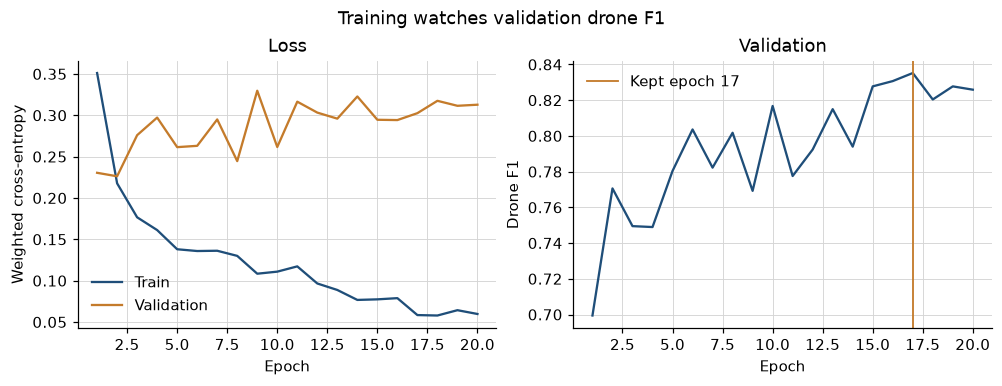

In [3]:
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

FEATURES_DIR = Path.cwd() / "features"
MODELS_DIR = Path.cwd() / "models"
MAX_EPOCHS = 20
PATIENCE = 5
BATCH_SIZE = 64
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.01


def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)


def mask_spectrogram(spec):
    """Train-only mask. A masked cell is set to 0, the training mean after scaling."""
    spec = spec.clone()
    n_mels, n_frames = spec.shape
    for _ in range(2):
        width = int(torch.randint(0, 12, (1,)))
        start = int(torch.randint(0, n_mels - width + 1, (1,)))
        spec[start:start + width, :] = 0
    for _ in range(2):
        width = int(torch.randint(0, 8, (1,)))
        start = int(torch.randint(0, n_frames - width + 1, (1,)))
        spec[:, start:start + width] = 0
    return spec


class WindowSet(Dataset):
    def __init__(self, mel, labels, augment=False):
        self.mel = mel
        self.labels = labels
        self.augment = augment

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        spec = torch.tensor(np.asarray(self.mel[index], dtype=np.float32))
        if self.augment:
            spec = mask_spectrogram(spec)
        return spec, int(self.labels[index])


def scores_from(labels, predicted, drone_probability):
    labels = np.asarray(labels)
    predicted = np.asarray(predicted)
    confusion = np.zeros((2, 2), dtype=int)
    for truth, guess in zip(labels, predicted):
        confusion[int(truth), int(guess)] += 1
    true_positive = confusion[1, 1]
    false_positive = confusion[0, 1]
    false_negative = confusion[1, 0]
    precision = true_positive / (true_positive + false_positive) if true_positive + false_positive else 0.0
    recall = true_positive / (true_positive + false_negative) if true_positive + false_negative else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    accuracy = (confusion[0, 0] + confusion[1, 1]) / confusion.sum()
    order = np.argsort(-np.asarray(drone_probability))
    ranked = labels[order]
    n_pos = max(int((labels == 1).sum()), 1)
    n_neg = max(int((labels == 0).sum()), 1)
    tpr = np.cumsum(ranked == 1) / n_pos
    fpr = np.cumsum(ranked == 0) / n_neg
    auc = float(np.trapezoid(np.r_[0.0, tpr], np.r_[0.0, fpr]))
    return {
        "accuracy": float(accuracy),
        "drone_precision": float(precision),
        "drone_recall": float(recall),
        "drone_f1": float(f1),
        "roc_auc": auc,
        "confusion": confusion,
    }


def run_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total = 0.0
    seen = 0
    for spectrogram, label in loader:
        spectrogram = spectrogram.to(device)
        label = label.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(spectrogram), label)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total += loss.item() * len(label)
        seen += len(label)
    return total / seen


@torch.no_grad()
def predict_split(model, loader, criterion, device):
    model.eval()
    total = 0.0
    seen = 0
    labels, predicted, probability = [], [], []
    for spectrogram, label in loader:
        spectrogram = spectrogram.to(device)
        label = label.to(device)
        logits = model(spectrogram)
        loss = criterion(logits, label)
        total += loss.item() * len(label)
        seen += len(label)
        labels.append(label.cpu().numpy())
        predicted.append(logits.argmax(dim=1).cpu().numpy())
        probability.append(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
    return total / seen, np.concatenate(labels), np.concatenate(predicted), np.concatenate(probability)
set_seed(SEED)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

# Training and validation only. The test files stay closed until evaluation.
train_mel = np.load(FEATURES_DIR / "train_logmel.npy")
train_y = np.load(FEATURES_DIR / "train_label.npy")
val_mel = np.load(FEATURES_DIR / "val_logmel.npy")
val_y = np.load(FEATURES_DIR / "val_label.npy")

counts = np.bincount(train_y, minlength=2).astype(np.float32)
class_weight = torch.tensor(counts.sum() / (2.0 * counts), dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=class_weight)

train_loader = DataLoader(
    WindowSet(train_mel, train_y, augment=True),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
val_loader = DataLoader(WindowSet(val_mel, val_y), batch_size=BATCH_SIZE, shuffle=False)

model = SpectrogramTransformer().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
schedule = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS)

history = []
best_f1 = -1.0
best_epoch = 0
best_state = None
wait = 0
for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = run_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_labels, val_pred, val_prob = predict_split(model, val_loader, criterion, device)
    val_scores = scores_from(val_labels, val_pred, val_prob)
    schedule.step()
    improved = val_scores["drone_f1"] > best_f1
    if improved:
        best_f1 = val_scores["drone_f1"]
        best_epoch = epoch
        best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
        wait = 0
    else:
        wait += 1
    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_accuracy": val_scores["accuracy"],
        "val_drone_precision": val_scores["drone_precision"],
        "val_drone_recall": val_scores["drone_recall"],
        "val_drone_f1": val_scores["drone_f1"],
        "kept": improved,
    })
    mark = "  kept" if improved else ""
    print(
        f"epoch {epoch:2d}  train loss {train_loss:.3f}  val loss {val_loss:.3f}  "
        f"val drone F1 {val_scores['drone_f1']:.3f}{mark}"
    )
    if wait >= PATIENCE:
        print(f"Stopped after epoch {epoch}. Validation drone F1 did not improve for {PATIENCE} epochs.")
        break

model.load_state_dict(best_state)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
checkpoint_path = MODELS_DIR / "spectrogram_transformer.pt"
torch.save({
    "state_dict": best_state,
    "epoch": best_epoch,
    "val_drone_f1": best_f1,
    "class_weight": class_weight.detach().cpu(),
    "config": {
        "n_mels": N_MELS,
        "n_frames": N_FRAMES,
        "patch_f": PATCH_F,
        "patch_t": PATCH_T,
        "d_model": D_MODEL,
        "n_heads": N_HEADS,
        "n_layers": N_LAYERS,
        "d_ff": D_FF,
        "dropout": DROPOUT,
        "n_classes": N_CLASSES,
    },
}, checkpoint_path)

history_frame = pd.DataFrame(history)
display(history_frame.style.format({
    "train_loss": "{:.3f}",
    "val_loss": "{:.3f}",
    "val_accuracy": "{:.3f}",
    "val_drone_precision": "{:.3f}",
    "val_drone_recall": "{:.3f}",
    "val_drone_f1": "{:.3f}",
}).hide(axis="index"))
print(f"Device: {device.type}")
print(f"Training windows: {len(train_y):,}  ({int(counts[1]):,} drone, {int(counts[0]):,} unknown)")
print(f"Class weights from the training counts: unknown {class_weight[0].item():.3f}, drone {class_weight[1].item():.3f}")
print(f"Kept epoch {best_epoch} with validation drone F1 {best_f1:.3f}")
print(f"Saved checkpoint: {checkpoint_path}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), layout="constrained")
axes[0].plot(history_frame.epoch, history_frame.train_loss, label="Train", color="#1f4e79")
axes[0].plot(history_frame.epoch, history_frame.val_loss, label="Validation", color="#c47b2b")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Weighted cross-entropy")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(history_frame.epoch, history_frame.val_drone_f1, color="#1f4e79")
axes[1].axvline(best_epoch, color="#c47b2b", linewidth=1.2, label=f"Kept epoch {best_epoch}")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Drone F1")
axes[1].set_title("Validation")
axes[1].legend()
fig.suptitle("Training watches validation drone F1", fontsize=12)
show(fig)


## 6. Evaluation (baseline transformer)

The saved checkpoint is scored once on the test split. Accuracy sits next to a baseline that always answers unknown, because that answer is already right for about 88% of windows. Drone precision, recall, F1, and ROC-AUC are the numbers that say whether the detector finds drones.


Model,Accuracy,Drone precision,Drone recall,Drone F1,ROC-AUC
Always unknown,0.878,0.000,0.000,0.000,0.500
Spectrogram transformer,0.991,0.944,0.984,0.964,0.998


Checkpoint: epoch 17, validation drone F1 0.835
Test windows: 1,559  (190 drone, 1,369 unknown)
Test weighted loss: 0.031
This is the only pass over the test split.


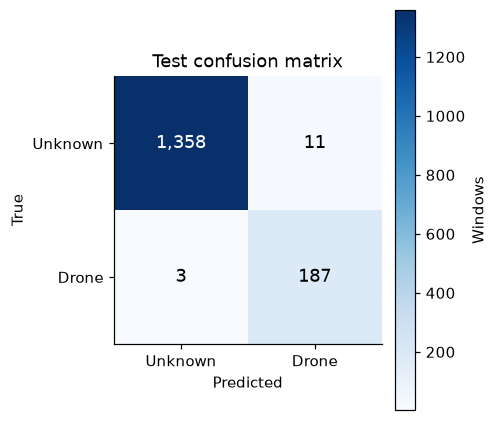

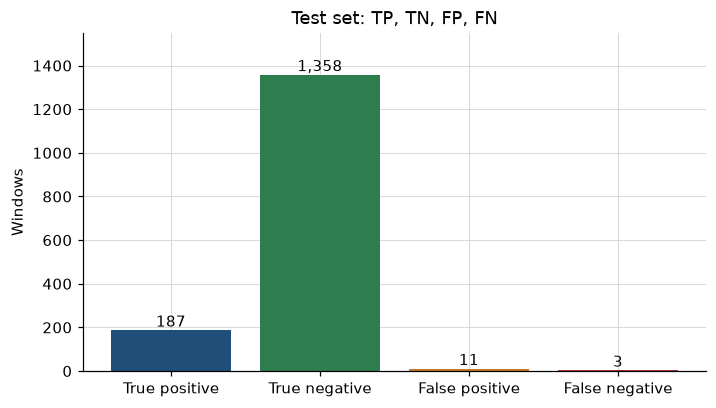

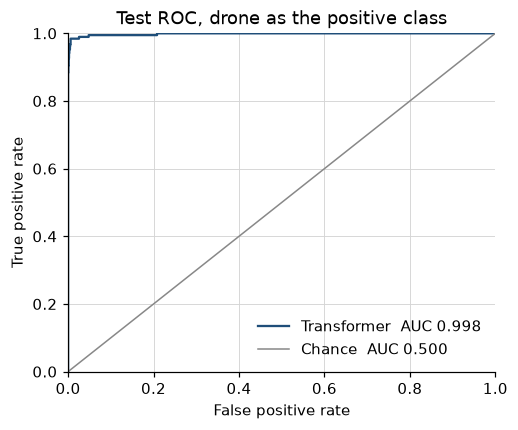

In [4]:
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader

FEATURES_DIR = Path.cwd() / "features"
checkpoint_path = Path.cwd() / "models" / "spectrogram_transformer.pt"
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

model = SpectrogramTransformer(**checkpoint["config"]).to(device)
model.load_state_dict(checkpoint["state_dict"])
class_weight = checkpoint["class_weight"].to(device)
criterion = nn.CrossEntropyLoss(weight=class_weight)

test_mel = np.load(FEATURES_DIR / "test_logmel.npy")
test_y = np.load(FEATURES_DIR / "test_label.npy")
test_loader = DataLoader(WindowSet(test_mel, test_y), batch_size=BATCH_SIZE, shuffle=False)
test_loss, labels, predicted, probability = predict_split(model, test_loader, criterion, device)
scores = scores_from(labels, predicted, probability)

majority_accuracy = float((labels == 0).mean())
comparison = pd.DataFrame([
    {
        "Model": "Always unknown",
        "Accuracy": majority_accuracy,
        "Drone precision": 0.0,
        "Drone recall": 0.0,
        "Drone F1": 0.0,
        "ROC-AUC": 0.5,
    },
    {
        "Model": "Spectrogram transformer",
        "Accuracy": scores["accuracy"],
        "Drone precision": scores["drone_precision"],
        "Drone recall": scores["drone_recall"],
        "Drone F1": scores["drone_f1"],
        "ROC-AUC": scores["roc_auc"],
    },
])
display(comparison.style.format({
    "Accuracy": "{:.3f}",
    "Drone precision": "{:.3f}",
    "Drone recall": "{:.3f}",
    "Drone F1": "{:.3f}",
    "ROC-AUC": "{:.3f}",
}).hide(axis="index"))
print(f"Checkpoint: epoch {checkpoint['epoch']}, validation drone F1 {checkpoint['val_drone_f1']:.3f}")
print(f"Test windows: {len(labels):,}  ({int((labels == 1).sum()):,} drone, {int((labels == 0).sum()):,} unknown)")
print(f"Test weighted loss: {test_loss:.3f}")
print("This is the only pass over the test split.")

confusion = scores["confusion"]
fig, ax = plt.subplots(figsize=(4.4, 3.8), layout="constrained")
image = ax.imshow(confusion, cmap="Blues")
ax.grid(False)
ax.set_xticks([0, 1], ["Unknown", "Drone"])
ax.set_yticks([0, 1], ["Unknown", "Drone"])
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Test confusion matrix")
for row in range(2):
    for col in range(2):
        color = "white" if confusion[row, col] > confusion.max() / 2 else "black"
        ax.text(col, row, f"{confusion[row, col]:,}", ha="center", va="center", color=color, fontsize=12)
fig.colorbar(image, ax=ax, label="Windows")
show(fig)

outcome = {
    "True positive": int(confusion[1, 1]),
    "True negative": int(confusion[0, 0]),
    "False positive": int(confusion[0, 1]),
    "False negative": int(confusion[1, 0]),
}
fig, ax = plt.subplots(figsize=(6.4, 3.6), layout="constrained")
names = list(outcome)
bars = ax.bar(
    names,
    list(outcome.values()),
    color=["#1f4e79", "#2e7d4f", "#c47b2b", "#a33b3b"],
)
ax.set_ylabel("Windows")
ax.set_title("Test set: TP, TN, FP, FN")
ax.set_ylim(0, max(outcome.values()) * 1.14)
for bar, value in zip(bars, outcome.values()):
    ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value:,}", ha="center", va="bottom", fontsize=10)
show(fig)

order = np.argsort(-probability)
ranked = labels[order]
n_pos = max(int((labels == 1).sum()), 1)
n_neg = max(int((labels == 0).sum()), 1)
tpr = np.r_[0.0, np.cumsum(ranked == 1) / n_pos]
fpr = np.r_[0.0, np.cumsum(ranked == 0) / n_neg]
fig, ax = plt.subplots(figsize=(4.6, 3.8), layout="constrained")
ax.plot(fpr, tpr, color="#1f4e79", label=f"Transformer  AUC {scores['roc_auc']:.3f}")
ax.plot([0, 1], [0, 1], color="#888888", linewidth=1, label="Chance  AUC 0.500")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Test ROC, drone as the positive class")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
show(fig)
